In [1]:
from pathlib import Path
import sys

if Path('/content').exists():
    ROOT = Path('/content/woodbench')
else:
    ROOT = Path.cwd()
    while ROOT != ROOT.parent and not (ROOT / 'docs' / 'references' / 'WoodID_plan.md').exists():
        ROOT = ROOT.parent

sys.path.insert(0, str(ROOT))
print(f'[ROOT] {ROOT}')


[ROOT] /home/sakana/Code/ManifoldsTeam/woodbench


# WoodID-S2-2026 — Phase 1 Run Report

Notebook này gom toàn bộ các lần chạy Phase 1 theo `docs/references/WoodID_plan.md`:

- Task A family-level: 5 backbone x 3 seed, không dùng W&B, trích thủ công từ output notebook gốc.
- Task B species-level main: 5 backbone x 3 seed, lấy từ W&B project `woodbench-taskB`.
- Task B ablation 90-degree rotation: 5 backbone, seed 42, lấy từ W&B.
- Task B ablation label smoothing: 5 backbone, seed 42, các mức label smoothing tìm theo W&B run name.
- Leakage-check clean data: `swin_tiny_90rot_clean_s42`, lấy từ W&B.

Notebook ưu tiên reproducibility: mọi bảng raw được cache về `reports/phase1_run_report/` để kiểm soát, đối chiếu, và dùng lại khi W&B offline.


In [2]:
if Path('/content').exists():
    import subprocess
    subprocess.check_call([
        sys.executable, '-m', 'pip', 'install', '-q',
        'wandb', 'pandas', 'matplotlib', 'seaborn', 'python-dotenv'
    ])


In [3]:
import json
import os
import re
from datetime import datetime
from pathlib import Path

os.environ.setdefault('MPLCONFIGDIR', '/tmp/matplotlib')
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from IPython.display import display

try:
    from dotenv import load_dotenv
    load_dotenv(ROOT / '.env')
except Exception as exc:
    print(f'[dotenv] skip: {exc}')

pd.set_option('display.max_columns', 80)
pd.set_option('display.width', 160)
sns.set_theme(style='whitegrid', context='notebook')

REPORT_DIR = ROOT / 'reports' / 'phase1_run_report'
REPORT_DIR.mkdir(parents=True, exist_ok=True)

PLAN_PATH = ROOT / 'docs' / 'references' / 'WoodID_plan.md'
TASK_A_DIR = ROOT / 'notebooks' / 'phase 1' / 'task-A'
TASK_B_DIR = ROOT / 'notebooks' / 'phase 1' / 'task-B'

WANDB_ENTITY = os.getenv('WANDB_ENTITY', 'ny0g507h3p_')
WANDB_PROJECT = os.getenv('WANDB_PROJECT', 'woodbench-taskB')
WANDB_PATH = f'{WANDB_ENTITY}/{WANDB_PROJECT}'

BACKBONES = ['resnet50', 'efficientnet_b3', 'mobilenetv3_large', 'convnext_tiny', 'swin_tiny']
SEEDS_MAIN = [42, 123, 456]
SEEDS_ABLATION = [42]
LS_VALUES = ['0.0', '0.2']

print(f'[report] {REPORT_DIR}')
print(f'[wandb] {WANDB_PATH}; key={"set" if os.getenv("WANDB_API_KEY") else "MISSING"}')


[report] /home/sakana/Code/ManifoldsTeam/woodbench/reports/phase1_run_report
[wandb] ny0g507h3p_/woodbench-taskB; key=set


## 1. Alignment với WoodID plan

Cell này kiểm tra nhanh các yêu cầu Phase 1 có mặt trong manifest báo cáo hay chưa. Đây không thay thế phân tích khoa học, nhưng giúp tránh thiếu run khi gom bảng.


In [4]:
plan_text = PLAN_PATH.read_text(encoding='utf-8')
required_plan_terms = [
    'Task A', 'Task B', 'ResNet-50', 'EfficientNet-B3', 'MobileNetV3-Large',
    'ConvNeXt-Tiny', 'Swin-T', '90° rotation', 'label smoothing', '3 seeds',
]
plan_check = pd.DataFrame({
    'requirement': required_plan_terms,
    'found_in_plan': [term in plan_text for term in required_plan_terms],
})
plan_check


,requirement,found_in_plan
0,Task A,True
1,Task B,True
2,ResNet-50,True
3,EfficientNet-B3,True
4,MobileNetV3-Large,True
5,ConvNeXt-Tiny,True
6,Swin-T,True
7,90° rotation,True
8,label smoothing,True
9,3 seeds,True


In [5]:
manifest_rows = []
for seed in SEEDS_MAIN:
    for backbone in BACKBONES:
        manifest_rows.append({
            'group': 'Task A manual',
            'task': 'A-family',
            'backbone': backbone,
            'seed': seed,
            'source': str(TASK_A_DIR / f'seed-{seed}' / f'TaskA_{backbone}.ipynb'),
            'wandb_name': None,
        })
        manifest_rows.append({
            'group': 'Task B main',
            'task': 'B-species',
            'backbone': backbone,
            'seed': seed,
            'source': WANDB_PATH,
            'wandb_name': f'{backbone}_s{seed}_test',
        })

for backbone in BACKBONES:
    manifest_rows.append({
        'group': 'Task B ablation 90rot',
        'task': 'B-species',
        'backbone': backbone,
        'seed': 42,
        'source': WANDB_PATH,
        'wandb_name': f'{backbone}_90rot_s42',
    })
    for ls in LS_VALUES:
        manifest_rows.append({
            'group': 'Task B ablation label smoothing',
            'task': 'B-species',
            'backbone': backbone,
            'seed': 42,
            'label_smoothing': float(ls),
            'source': WANDB_PATH,
            'wandb_name': f'{backbone}_ls{ls}_s42',
        })

manifest_rows.append({
    'group': 'Task B clean leakage-check',
    'task': 'B-species-clean',
    'backbone': 'swin_tiny',
    'seed': 42,
    'source': WANDB_PATH,
    'wandb_name': 'swin_tiny_90rot_clean_s42',
})

manifest = pd.DataFrame(manifest_rows)
manifest.to_csv(REPORT_DIR / 'phase1_manifest.csv', index=False)
manifest.groupby('group').size().rename('expected_runs').reset_index()


,group,expected_runs
0,Task A manual,15
1,Task B ablation 90rot,5
2,Task B ablation label smoothing,10
3,Task B clean leakage-check,1
4,Task B main,15


## 2. Task A — trích thủ công từ notebook output

Task A không dùng W&B. Hàm dưới đây đọc output text đã lưu trong các notebook `task-A/seed-*/TaskA_*.ipynb` và bắt các dòng summary phổ biến như `Best val accuracy`, `Test accuracy`, `Test F1-macro`, `Test Precision`, `Test Recall`.


In [6]:
def _cell_output_text(cell):
    chunks = []
    for out in cell.get('outputs', []):
        if 'text' in out:
            text = out['text']
            chunks.append(''.join(text) if isinstance(text, list) else str(text))
        data = out.get('data', {})
        for key in ('text/plain', 'text/markdown'):
            if key in data:
                text = data[key]
                chunks.append(''.join(text) if isinstance(text, list) else str(text))
    return '\n'.join(chunks)


def _extract_percent(patterns, text):
    values = []
    for pattern in patterns:
        for match in re.finditer(pattern, text, flags=re.IGNORECASE | re.MULTILINE):
            values.append(float(match.group(1)) / 100.0)
    return max(values) if values else None


def _extract_best_epoch(text, best_val=None):
    candidates = []

    for match in re.finditer(r'Best val accuracy:\s*([0-9.]+)%\s*\(epoch\s*(\d+)\)', text, flags=re.IGNORECASE | re.MULTILINE):
        candidates.append((int(match.group(2)), float(match.group(1)) / 100.0))
    for match in re.finditer(r'Loaded best:\s*epoch\s*(\d+),\s*val_acc=([0-9.]+)%', text, flags=re.IGNORECASE | re.MULTILINE):
        candidates.append((int(match.group(1)), float(match.group(2)) / 100.0))

    current_epoch = None
    for line in text.splitlines():
        epoch_match = re.search(r'Epoch\s+(\d+)\s*/\s*\d+', line, flags=re.IGNORECASE)
        if epoch_match:
            current_epoch = int(epoch_match.group(1))
        val_match = re.search(r'Val Loss:\s*[0-9.]+,\s*Acc:\s*([0-9.]+)%', line, flags=re.IGNORECASE)
        if val_match and current_epoch is not None:
            candidates.append((current_epoch, float(val_match.group(1)) / 100.0))
        best_match = re.search(r'New best!.*?Val Acc:\s*([0-9.]+)%', line, flags=re.IGNORECASE)
        if best_match and current_epoch is not None:
            candidates.append((current_epoch, float(best_match.group(1)) / 100.0))

    if not candidates:
        return None
    if best_val is not None:
        near = [item for item in candidates if item[1] is not None and abs(item[1] - best_val) < 5e-4]
        if near:
            return min(near, key=lambda item: item[0])[0]
    return max(candidates, key=lambda item: (-1 if item[1] is None else item[1], item[0]))[0]


def extract_task_a_notebook(path):
    nb = json.loads(path.read_text(encoding='utf-8'))
    text = '\n'.join(_cell_output_text(cell) for cell in nb.get('cells', []))
    seed_match = re.search(r'seed-(\d+)', str(path))
    backbone = path.stem.replace('TaskA_', '')

    best_val = _extract_percent([
        r'Best val accuracy:\s*([0-9.]+)%',
        r'val_acc=([0-9.]+)%',
        r'Val Acc:\s*([0-9.]+)%',
    ], text)
    test_acc = _extract_percent([
        r'Test accuracy:\s*([0-9.]+)%',
        r'TEST Acc=([0-9.]+)%',
        r'^Accuracy:\s*([0-9.]+)%',
        r'accuracy\s+([0-9.]+)\s+\d+',
    ], text)
    test_f1 = _extract_percent([
        r'Test F1-macro:\s*([0-9.]+)%',
        r'F1=([0-9.]+)%',
        r'^F1-macro:\s*([0-9.]+)%',
        r'macro avg\s+[0-9.]+\s+[0-9.]+\s+([0-9.]+)',
    ], text)
    test_precision = _extract_percent([
        r'Test Precision:\s*([0-9.]+)%',
        r'Prec=([0-9.]+)%',
        r'^Precision:\s*([0-9.]+)%',
    ], text)
    test_recall = _extract_percent([
        r'Test Recall:\s*([0-9.]+)%',
        r'Rec=([0-9.]+)%',
        r'^Recall:\s*([0-9.]+)%',
    ], text)
    best_epoch = _extract_best_epoch(text, best_val)

    return {
        'group': 'Task A manual',
        'task': 'A-family',
        'backbone': backbone,
        'seed': int(seed_match.group(1)) if seed_match else None,
        'run_name': path.stem,
        'state': 'notebook-output',
        'best_val_acc': best_val,
        'best_epoch': best_epoch,
        'test_accuracy': test_acc,
        'test_f1_macro': test_f1,
        'test_precision_macro': test_precision,
        'test_recall_macro': test_recall,
        'source_path': str(path.relative_to(ROOT)),
    }


task_a_rows = [extract_task_a_notebook(p) for p in sorted(TASK_A_DIR.glob('seed-*/TaskA_*.ipynb'))]
task_a = pd.DataFrame(task_a_rows).sort_values(['backbone', 'seed'])
task_a.to_csv(REPORT_DIR / 'task_a_manual_raw.csv', index=False)
task_a


,group,task,backbone,seed,run_name,state,best_val_acc,best_epoch,test_accuracy,test_f1_macro,test_precision_macro,test_recall_macro,source_path
5,Task A manual,A-family,convnext_tiny,42,TaskA_convnext_tiny,notebook-output,1.0000,10,0.9990,0.9969,0.9946,0.9993,notebooks/phase 1/task-A/seed-42/TaskA_convnex...
0,Task A manual,A-family,convnext_tiny,123,TaskA_convnext_tiny,notebook-output,1.0000,7,1.0000,1.0000,1.0000,1.0000,notebooks/phase 1/task-A/seed-123/TaskA_convne...
10,Task A manual,A-family,convnext_tiny,456,TaskA_convnext_tiny,notebook-output,1.0000,4,0.9980,0.9941,0.9894,0.9990,notebooks/phase 1/task-A/seed-456/TaskA_convne...
6,Task A manual,A-family,efficientnet_b3,42,TaskA_efficientnet_b3,notebook-output,0.9990,18,0.9929,0.9840,0.9831,0.9857,notebooks/phase 1/task-A/seed-42/TaskA_efficie...
1,Task A manual,A-family,efficientnet_b3,123,TaskA_efficientnet_b3,notebook-output,0.9990,14,0.9939,0.9843,0.9875,0.9815,notebooks/phase 1/task-A/seed-123/TaskA_effici...
11,Task A manual,A-family,efficientnet_b3,456,TaskA_efficientnet_b3,notebook-output,0.9990,12,0.9939,0.9894,0.9879,0.9912,notebooks/phase 1/task-A/seed-456/TaskA_effici...
7,Task A manual,A-family,mobilenetv3_large,42,TaskA_mobilenetv3_large,notebook-output,0.9958,23,0.9908,0.9831,0.9764,0.9902,notebooks/phase 1/task-A/seed-42/TaskA_mobilen...
2,Task A manual,A-family,mobilenetv3_large,123,TaskA_mobilenetv3_large,notebook-output,0.9969,23,0.9918,0.9905,0.9906,0.9905,notebooks/phase 1/task-A/seed-123/TaskA_mobile...
12,Task A manual,A-family,mobilenetv3_large,456,TaskA_mobilenetv3_large,notebook-output,0.9958,23,0.9918,0.9883,0.9861,0.9907,notebooks/phase 1/task-A/seed-456/TaskA_mobile...
8,Task A manual,A-family,resnet50,42,TaskA_resnet50,notebook-output,0.9916,40,0.9817,0.9576,0.9376,0.9802,notebooks/phase 1/task-A/seed-42/TaskA_resnet5...


In [7]:
task_a_required = ['best_epoch', 'best_val_acc', 'test_accuracy', 'test_f1_macro']
task_a_missing = task_a[task_a[task_a_required].isna().any(axis=1)]
print(f'Task A parsed rows: {len(task_a)}')
print(f'Rows needing manual review: {len(task_a_missing)}')
task_a_missing[['backbone', 'seed', 'best_epoch', 'best_val_acc', 'test_accuracy', 'test_f1_macro', 'source_path']]


Task A parsed rows: 15
Rows needing manual review: 0


,backbone,seed,best_epoch,best_val_acc,test_accuracy,test_f1_macro,source_path


## 3. W&B — lấy log Task B, ablation, leakage-check

Cell này dùng API key từ `.env` hoặc biến môi trường. Nếu W&B tạm offline, đặt `FORCE_WANDB_FETCH = False` để dùng cache CSV đã có trong `reports/phase1_run_report/`.


In [8]:
FORCE_WANDB_FETCH = True
CACHE_WANDB_RAW = REPORT_DIR / 'wandb_phase1_raw.csv'

METRIC_ALIASES = {
    'best_val_acc': ['best_val_acc', 'val/acc', 'val_accuracy', 'val/accuracy'],
    'test_accuracy': ['test/accuracy', 'test_accuracy', 'accuracy'],
    'test_f1_macro': ['test/f1_macro', 'test/f1', 'test_f1_macro', 'f1_macro'],
    'test_precision_macro': ['test/precision_macro', 'test_precision_macro', 'precision_macro'],
    'test_recall_macro': ['test/recall_macro', 'test_recall_macro', 'recall_macro'],
    'train_loss': ['train/loss', 'train_loss'],
    'val_loss': ['val/loss', 'val_loss'],
}


def _summary_get(summary, aliases):
    for key in aliases:
        value = summary.get(key)
        if value is not None:
            try:
                return float(value)
            except (TypeError, ValueError):
                return value
    return None


def _run_row(run, group, task, backbone, seed, expected_name, label_smoothing=None):
    summary = dict(run.summary)
    row = {
        'group': group,
        'task': task,
        'backbone': backbone,
        'seed': seed,
        'label_smoothing': label_smoothing,
        'expected_name': expected_name,
        'run_name': run.name,
        'run_id': run.id,
        'state': run.state,
        'url': run.url,
        'created_at': str(getattr(run, 'created_at', '')),
        'tags': ','.join(run.tags or []),
    }
    for out_key, aliases in METRIC_ALIASES.items():
        value = _summary_get(summary, aliases)
        if out_key != 'train_loss' and out_key != 'val_loss' and isinstance(value, (int, float)) and abs(value) > 1:
            value = value / 100.0
        row[out_key] = value
    return row


def fetch_wandb_rows(expected_manifest):
    import wandb

    api = wandb.Api()
    runs = list(api.runs(WANDB_PATH))
    by_name = {}
    for run in runs:
        by_name.setdefault(run.name, []).append(run)

    rows = []
    for item in expected_manifest.dropna(subset=['wandb_name']).to_dict('records'):
        matches = by_name.get(item['wandb_name'], [])
        if not matches:
            rows.append({
                'group': item['group'], 'task': item['task'], 'backbone': item['backbone'],
                'seed': item['seed'], 'label_smoothing': item.get('label_smoothing'),
                'expected_name': item['wandb_name'], 'run_name': None, 'run_id': None,
                'state': 'missing', 'url': None,
            })
            continue
        # Prefer finished metric-bearing runs; if duplicates exist, keep the newest by created_at string.
        def _match_score(candidate):
            summary = dict(candidate.summary)
            metric_count = sum(1 for key in summary if any(token in key.lower() for token in ['test', 'val', 'acc', 'f1']))
            return (candidate.state == 'finished', metric_count, str(getattr(candidate, 'created_at', '')))
        matches = sorted(matches, key=_match_score, reverse=True)
        run = matches[0]
        rows.append(_run_row(
            run=run,
            group=item['group'],
            task=item['task'],
            backbone=item['backbone'],
            seed=int(item['seed']) if pd.notna(item['seed']) else None,
            expected_name=item['wandb_name'],
            label_smoothing=item.get('label_smoothing'),
        ))
    return pd.DataFrame(rows)


wandb_manifest = manifest[manifest['wandb_name'].notna()].copy()
if FORCE_WANDB_FETCH or not CACHE_WANDB_RAW.exists():
    wandb_df = fetch_wandb_rows(wandb_manifest)
    wandb_df.to_csv(CACHE_WANDB_RAW, index=False)
else:
    wandb_df = pd.read_csv(CACHE_WANDB_RAW)


def extract_task_b_main_notebook_metrics():
    rows = []
    for path in sorted((TASK_B_DIR / 'M1_main').glob('TaskB_*.ipynb')):
        backbone = path.stem.replace('TaskB_', '')
        nb = json.loads(path.read_text(encoding='utf-8'))
        text = '\n'.join(_cell_output_text(cell) for cell in nb.get('cells', []))
        for match in re.finditer(r'\[([^\]\s]+)\s+s(\d+)\]\s+val_acc=([0-9.]+)%', text, flags=re.IGNORECASE):
            rows.append({
                'group': 'Task B main',
                'task': 'B-species',
                'backbone': backbone,
                'seed': int(match.group(2)),
                'best_val_acc_notebook': float(match.group(3)) / 100.0,
                'source_path': str(path.relative_to(ROOT)),
            })
    return pd.DataFrame(rows)


def extract_task_b_eval_metrics():
    path = TASK_B_DIR / 'M1_eval' / 'TaskB_Evaluate.ipynb'
    if not path.exists():
        return pd.DataFrame()
    nb = json.loads(path.read_text(encoding='utf-8'))
    text = '\n'.join(_cell_output_text(cell) for cell in nb.get('cells', []))
    rows = []
    row_pattern = re.compile(
        r'\s*(.+?)_seed(\d+)\s+(\d+)\s+(\d+)\s+([0-9.]+)%\s+([0-9.]+)%\s+([0-9.]+)%\s+([0-9.]+)%\s+([0-9.]+)%'
    )
    for line in text.splitlines():
        match = row_pattern.match(line)
        if not match:
            continue
        backbone, seed, seed_col, epochs, best_val, acc, prec, rec, f1 = match.groups()
        rows.append({
            'group': 'Task B main',
            'task': 'B-species',
            'backbone': backbone,
            'seed': int(seed),
            'epochs_trained_eval': int(epochs),
            'best_val_acc_eval': float(best_val) / 100.0,
            'test_accuracy_eval': float(acc) / 100.0,
            'test_precision_macro_eval': float(prec) / 100.0,
            'test_recall_macro_eval': float(rec) / 100.0,
            'test_f1_macro_eval': float(f1) / 100.0,
            'eval_source_path': str(path.relative_to(ROOT)),
        })
    return pd.DataFrame(rows)


task_b_main_notebook = extract_task_b_main_notebook_metrics()
task_b_main_notebook.to_csv(REPORT_DIR / 'task_b_main_notebook_metrics.csv', index=False)
task_b_eval_metrics = extract_task_b_eval_metrics()
task_b_eval_metrics.to_csv(REPORT_DIR / 'task_b_main_eval_metrics.csv', index=False)

if not task_b_main_notebook.empty:
    fallback = task_b_main_notebook[['backbone', 'seed', 'best_val_acc_notebook', 'source_path']].copy()
    fallback = fallback.rename(columns={'source_path': 'notebook_source_path'})
    wandb_df = wandb_df.merge(fallback, on=['backbone', 'seed'], how='left')
    main_mask = wandb_df['group'].eq('Task B main')
    wandb_df.loc[main_mask, 'best_val_acc'] = wandb_df.loc[main_mask, 'best_val_acc'].fillna(wandb_df.loc[main_mask, 'best_val_acc_notebook'])
    if 'source_path' not in wandb_df.columns:
        wandb_df['source_path'] = pd.NA
    wandb_df.loc[main_mask, 'source_path'] = wandb_df.loc[main_mask, 'source_path'].fillna(wandb_df.loc[main_mask, 'notebook_source_path'])
    wandb_df = wandb_df.drop(columns=[c for c in ['best_val_acc_notebook', 'notebook_source_path'] if c in wandb_df.columns])

if not task_b_eval_metrics.empty:
    fallback = task_b_eval_metrics[[
        'backbone', 'seed', 'epochs_trained_eval', 'best_val_acc_eval', 'test_accuracy_eval',
        'test_precision_macro_eval', 'test_recall_macro_eval', 'test_f1_macro_eval', 'eval_source_path'
    ]].copy()
    wandb_df = wandb_df.merge(fallback, on=['backbone', 'seed'], how='left')
    main_mask = wandb_df['group'].eq('Task B main')
    metric_pairs = {
        'best_val_acc': 'best_val_acc_eval',
        'test_accuracy': 'test_accuracy_eval',
        'test_precision_macro': 'test_precision_macro_eval',
        'test_recall_macro': 'test_recall_macro_eval',
        'test_f1_macro': 'test_f1_macro_eval',
    }
    for target, source in metric_pairs.items():
        wandb_df.loc[main_mask, target] = wandb_df.loc[main_mask, source].combine_first(wandb_df.loc[main_mask, target])
    if 'source_path' not in wandb_df.columns:
        wandb_df['source_path'] = pd.NA
    wandb_df.loc[main_mask, 'source_path'] = wandb_df.loc[main_mask, 'source_path'].fillna(wandb_df.loc[main_mask, 'eval_source_path'])
    wandb_df.loc[main_mask, 'epochs_trained'] = wandb_df.loc[main_mask, 'epochs_trained_eval']
    drop_cols = [
        'epochs_trained_eval', 'best_val_acc_eval', 'test_accuracy_eval', 'test_precision_macro_eval',
        'test_recall_macro_eval', 'test_f1_macro_eval', 'eval_source_path'
    ]
    wandb_df = wandb_df.drop(columns=[c for c in drop_cols if c in wandb_df.columns])



def _task_b_group_from_path(path):
    path_str = str(path)
    if '/M1_main/' in path_str:
        return 'Task B main', 'B-species'
    if '/M2_ablation/3.1_90rotation/' in path_str:
        return 'Task B ablation 90rot', 'B-species'
    if '/M2_ablation/3.2_label_smoothing/' in path_str:
        return 'Task B ablation label smoothing', 'B-species'
    if '/leakage-check/' in path_str:
        return 'Task B clean leakage-check', 'B-species-clean'
    return None, None


def _backbone_from_task_b_path(path):
    stem = path.stem
    for prefix in ['TaskB_90rot_', 'TaskB_ls_', 'TaskB_']:
        if stem.startswith(prefix):
            return stem.replace(prefix, '')
    return stem


def extract_notebook_learning_curves():
    rows = []
    epoch_pattern = re.compile(
        r'Epoch\s+(\d+)\s*/\s*(\d+)\s*\|\s*'
        r'Train Loss:\s*([0-9.]+),\s*Acc:\s*([0-9.]+)%\s*\|\s*'
        r'Val Loss:\s*([0-9.]+),\s*Acc:\s*([0-9.]+)%\s*\|\s*'
        r'LR:\s*([0-9.eE+-]+)'
    )

    # Task A notebooks: one seed/backbone per notebook.
    for path in sorted(TASK_A_DIR.glob('seed-*/TaskA_*.ipynb')):
        seed_match = re.search(r'seed-(\d+)', str(path))
        seed = int(seed_match.group(1)) if seed_match else None
        backbone = path.stem.replace('TaskA_', '')
        nb = json.loads(path.read_text(encoding='utf-8'))
        text = '\n'.join(_cell_output_text(cell) for cell in nb.get('cells', []))
        for line in text.splitlines():
            match = epoch_pattern.search(line)
            if not match:
                continue
            epoch, total_epochs, train_loss, train_acc, val_loss, val_acc, lr = match.groups()
            rows.append({
                'group': 'Task A manual', 'task': 'A-family', 'backbone': backbone, 'seed': seed,
                'label_smoothing': None, 'epoch': int(epoch), 'total_epochs': int(total_epochs),
                'train_loss': float(train_loss), 'train_acc': float(train_acc) / 100.0,
                'val_loss': float(val_loss), 'val_acc': float(val_acc) / 100.0,
                'lr': float(lr), 'source_path': str(path.relative_to(ROOT)),
            })

    # Task B notebooks: seed/label-smoothing are inferred from nearby log context.
    for path in sorted(TASK_B_DIR.rglob('*.ipynb')):
        if '/M1_eval/' in str(path) or '/M1_eval\\' in str(path):
            continue
        group, task = _task_b_group_from_path(path)
        if group is None:
            continue
        path_backbone = _backbone_from_task_b_path(path)
        nb = json.loads(path.read_text(encoding='utf-8'))
        text = '\n'.join(_cell_output_text(cell) for cell in nb.get('cells', []))
        current_seed = None
        current_ls = None
        current_backbone = path_backbone
        for line in text.splitlines():
            ls_context = re.search(r'Label Smoothing=([0-9.]+).*?seed=(\d+)', line, flags=re.IGNORECASE)
            if ls_context:
                current_ls = float(ls_context.group(1))
                current_seed = int(ls_context.group(2))
            bracket_context = re.search(r'\[([^\]\s]+)\s+s(\d+)(?:\s+LS=([0-9.]+))?\]', line, flags=re.IGNORECASE)
            if bracket_context:
                current_backbone = bracket_context.group(1)
                current_seed = int(bracket_context.group(2))
                if bracket_context.group(3) is not None:
                    current_ls = float(bracket_context.group(3))
            seed_context = re.search(r'\|\s*seed=(\d+)', line, flags=re.IGNORECASE)
            if seed_context and 'Label Smoothing=' not in line:
                current_seed = int(seed_context.group(1))
                if group != 'Task B ablation label smoothing':
                    current_ls = None
            match = epoch_pattern.search(line)
            if not match:
                continue
            epoch, total_epochs, train_loss, train_acc, val_loss, val_acc, lr = match.groups()
            rows.append({
                'group': group, 'task': task, 'backbone': current_backbone, 'seed': current_seed,
                'label_smoothing': current_ls, 'epoch': int(epoch), 'total_epochs': int(total_epochs),
                'train_loss': float(train_loss), 'train_acc': float(train_acc) / 100.0,
                'val_loss': float(val_loss), 'val_acc': float(val_acc) / 100.0,
                'lr': float(lr), 'source_path': str(path.relative_to(ROOT)),
            })
    return pd.DataFrame(rows)


notebook_learning_curves = extract_notebook_learning_curves()
notebook_learning_curves.to_csv(REPORT_DIR / 'learning_curves_from_notebooks.csv', index=False)

if not notebook_learning_curves.empty:
    curve_key = notebook_learning_curves.copy()
    curve_key['label_smoothing_key'] = curve_key['label_smoothing'].fillna('__NA__').astype(str)
    best_rows = []
    for keys, part in curve_key.dropna(subset=['val_acc']).groupby(['group', 'backbone', 'seed', 'label_smoothing_key'], dropna=False):
        ordered = part.sort_values(['val_acc', 'epoch'], ascending=[False, True])
        best = ordered.iloc[0]
        best_rows.append({
            'group': keys[0], 'backbone': keys[1], 'seed': keys[2], 'label_smoothing_key': keys[3],
            'best_epoch_curve': int(best['epoch']),
            'best_val_acc_curve': float(best['val_acc']),
            'curve_source_path': best['source_path'],
        })
    best_epochs_from_curves = pd.DataFrame(best_rows)
else:
    best_epochs_from_curves = pd.DataFrame(columns=['group', 'backbone', 'seed', 'label_smoothing_key', 'best_epoch_curve', 'best_val_acc_curve', 'curve_source_path'])

best_epochs_from_curves.to_csv(REPORT_DIR / 'best_epochs_from_learning_curves.csv', index=False)

if not best_epochs_from_curves.empty:
    if 'best_epoch' not in wandb_df.columns:
        wandb_df['best_epoch'] = pd.NA
    wandb_df['label_smoothing_key'] = wandb_df['label_smoothing'].fillna('__NA__').astype(str)
    wandb_df = wandb_df.merge(best_epochs_from_curves, on=['group', 'backbone', 'seed', 'label_smoothing_key'], how='left')
    fill_mask = wandb_df['best_epoch'].isna() & wandb_df['best_epoch_curve'].notna()
    wandb_df.loc[fill_mask, 'best_epoch'] = wandb_df.loc[fill_mask, 'best_epoch_curve']
    # For rows with parsed curves, use the curve maximum as true best-val accuracy so it matches best_epoch.
    val_fill_mask = wandb_df['best_val_acc_curve'].notna()
    wandb_df.loc[val_fill_mask, 'best_val_acc'] = wandb_df.loc[val_fill_mask, 'best_val_acc_curve']
    if 'source_path' not in wandb_df.columns:
        wandb_df['source_path'] = pd.NA
    src_fill_mask = wandb_df['source_path'].isna() & wandb_df['curve_source_path'].notna()
    wandb_df.loc[src_fill_mask, 'source_path'] = wandb_df.loc[src_fill_mask, 'curve_source_path']
    wandb_df = wandb_df.drop(columns=[c for c in ['label_smoothing_key', 'best_epoch_curve', 'best_val_acc_curve', 'curve_source_path'] if c in wandb_df.columns])

wandb_df.to_csv(CACHE_WANDB_RAW, index=False)

wandb_df.sort_values(['group', 'backbone', 'seed', 'expected_name']).reset_index(drop=True)


wandb: [wandb.Api()] Loaded credentials for https://api.wandb.ai from WANDB_API_KEY.


,group,task,backbone,seed,label_smoothing,expected_name,run_name,run_id,state,url,created_at,tags,best_val_acc,test_accuracy,test_f1_macro,test_precision_macro,test_recall_macro,train_loss,val_loss,source_path,epochs_trained
0,Task B ablation 90rot,B-species,convnext_tiny,42,NaN,convnext_tiny_90rot_s42,convnext_tiny_90rot_s42,hudk38su,finished,https://wandb.ai/ny0g507h3p_/woodbench-taskB/r...,2026-05-27T06:27:33Z,"90rotation,ablation,convnext_tiny,seed42",1.000000,0.995671,0.995870,0.995926,0.995939,0.594114,0.595058,<NA>,NaN
1,Task B ablation 90rot,B-species,efficientnet_b3,42,NaN,efficientnet_b3_90rot_s42,efficientnet_b3_90rot_s42,f7wvhp6i,finished,https://wandb.ai/ny0g507h3p_/woodbench-taskB/r...,2026-05-27T06:28:18Z,"90rotation,ablation,efficientnet_b3,seed42",0.991426,0.992424,0.992268,0.992064,0.992649,0.655300,0.634462,<NA>,NaN
2,Task B ablation 90rot,B-species,mobilenetv3_large,42,NaN,mobilenetv3_large_90rot_s42,mobilenetv3_large_90rot_s42,r1xv463h,finished,https://wandb.ai/ny0g507h3p_/woodbench-taskB/r...,2026-05-27T06:49:23Z,"90rotation,ablation,mobilenetv3_large,seed42",0.995713,0.994589,0.994647,0.994838,0.994531,0.670759,0.663014,<NA>,NaN
3,Task B ablation 90rot,B-species,resnet50,42,NaN,resnet50_90rot_s42,resnet50_90rot_s42,tsbyyjf6,finished,https://wandb.ai/ny0g507h3p_/woodbench-taskB/r...,2026-05-27T06:28:22Z,"90rotation,ablation,resnet50,seed42",0.964630,0.962121,0.962195,0.963512,0.962450,0.812247,0.767552,<NA>,NaN
4,Task B ablation 90rot,B-species,swin_tiny,42,NaN,swin_tiny_90rot_s42,swin_tiny_90rot_s42,4z7t55es,finished,https://wandb.ai/ny0g507h3p_/woodbench-taskB/r...,2026-05-27T06:49:26Z,"90rotation,ablation,seed42,swin_tiny",0.993569,0.993506,0.993530,0.994146,0.993328,0.605363,0.615540,<NA>,NaN
5,Task B ablation label smoothing,B-species,convnext_tiny,42,0.0,convnext_tiny_ls0.0_s42,convnext_tiny_ls0.0_s42,0mohlruw,finished,https://wandb.ai/ny0g507h3p_/woodbench-taskB/r...,2026-06-19T08:47:45Z,"ablation,convnext_tiny,label_smoothing_0.0,seed42",0.994641,0.996753,0.996776,0.996896,0.996746,0.012672,0.015048,<NA>,NaN
6,Task B ablation label smoothing,B-species,convnext_tiny,42,0.2,convnext_tiny_ls0.2_s42,convnext_tiny_ls0.2_s42,qv3tmqpa,finished,https://wandb.ai/ny0g507h3p_/woodbench-taskB/r...,2026-06-19T09:39:41Z,"ablation,convnext_tiny,label_smoothing_0.2,seed42",1.000000,0.996753,0.996709,0.996715,0.996750,1.054375,1.048450,<NA>,NaN
7,Task B ablation label smoothing,B-species,efficientnet_b3,42,0.0,efficientnet_b3_ls0.0_s42,efficientnet_b3_ls0.0_s42,efqvbq8i,finished,https://wandb.ai/ny0g507h3p_/woodbench-taskB/r...,2026-06-19T09:24:27Z,"ablation,efficientnet_b3,label_smoothing_0.0,s...",0.991426,0.987013,0.987626,0.987680,0.987752,0.032850,0.039773,<NA>,NaN
8,Task B ablation label smoothing,B-species,efficientnet_b3,42,0.2,efficientnet_b3_ls0.2_s42,efficientnet_b3_ls0.2_s42,a9fgrcqh,finished,https://wandb.ai/ny0g507h3p_/woodbench-taskB/r...,2026-06-19T10:20:21Z,"ablation,efficientnet_b3,label_smoothing_0.2,s...",0.993569,0.991342,0.991510,0.991544,0.991672,1.109387,1.116047,<NA>,NaN
9,Task B ablation label smoothing,B-species,mobilenetv3_large,42,0.0,mobilenetv3_large_ls0.0_s42,mobilenetv3_large_ls0.0_s42,di6jt3e5,finished,https://wandb.ai/ny0g507h3p_/woodbench-taskB/r...,2026-06-19T08:48:12Z,"ablation,label_smoothing_0.0,mobilenetv3_large...",0.991426,0.987013,0.986783,0.987257,0.986901,0.031296,0.026635,<NA>,NaN


In [9]:
wandb_status = (wandb_df
    .groupby(['group', 'state'])
    .size()
    .rename('runs')
    .reset_index()
    .sort_values(['group', 'state']))
wandb_status


,group,state,runs
0,Task B ablation 90rot,finished,5
1,Task B ablation label smoothing,finished,10
2,Task B clean leakage-check,finished,1
3,Task B main,finished,15


## 4. Tổng hợp bảng kết quả

Metric được giữ ở dạng tỷ lệ 0-1 trong bảng raw. Các bảng trình bày bên dưới nhân 100 để đọc như phần trăm.


In [10]:
raw_all = pd.concat([task_a, wandb_df], ignore_index=True, sort=False)
raw_all.to_csv(REPORT_DIR / 'phase1_all_runs_raw.csv', index=False)

metric_cols = ['best_val_acc', 'test_accuracy', 'test_f1_macro', 'test_precision_macro', 'test_recall_macro']
summary_metric_cols = ['best_epoch'] + metric_cols

missing_required_by_group = {
    'Task A manual': ['best_epoch', 'best_val_acc', 'test_accuracy', 'test_f1_macro', 'test_precision_macro', 'test_recall_macro'],
    'Task B main': ['best_val_acc', 'test_accuracy', 'test_f1_macro', 'test_precision_macro', 'test_recall_macro'],
    'Task B ablation 90rot': ['best_val_acc', 'test_accuracy', 'test_f1_macro', 'test_precision_macro', 'test_recall_macro'],
    'Task B ablation label smoothing': ['best_val_acc', 'test_accuracy', 'test_f1_macro', 'test_precision_macro', 'test_recall_macro'],
    'Task B clean leakage-check': ['best_val_acc', 'test_accuracy', 'test_f1_macro', 'test_precision_macro', 'test_recall_macro'],
}
missing_rows = []
for _, row in raw_all.iterrows():
    for metric in missing_required_by_group.get(row.get('group'), []):
        if metric in raw_all.columns and pd.isna(row.get(metric)):
            missing_rows.append({
                'group': row.get('group'),
                'backbone': row.get('backbone'),
                'seed': row.get('seed'),
                'run_name': row.get('run_name'),
                'metric': metric,
                'source_path': row.get('source_path'),
                'url': row.get('url'),
            })
missing_metrics = pd.DataFrame(missing_rows)
missing_metrics.to_csv(REPORT_DIR / 'missing_metrics.csv', index=False)

def std0(series):
    return series.std(ddof=0)

summary = (raw_all
    .groupby(['group', 'task', 'backbone'], dropna=False)[summary_metric_cols]
    .agg(['mean', std0, 'count'])
    .reset_index())
summary.columns = ['_'.join([str(x) for x in col if x]) for col in summary.columns]
summary = summary.rename(columns={col: col.replace('_std0', '_std') for col in summary.columns})
summary.to_csv(REPORT_DIR / 'phase1_summary_by_group_backbone.csv', index=False)

summary_display = summary.copy()
for col in summary_display.columns:
    if any(metric in col for metric in metric_cols) and (col.endswith('_mean') or col.endswith('_std')):
        summary_display[col] = (summary_display[col] * 100).round(2)
    elif 'best_epoch' in col and (col.endswith('_mean') or col.endswith('_std')):
        summary_display[col] = summary_display[col].round(2)
summary_display.to_csv(REPORT_DIR / 'phase1_summary_by_group_backbone_percent.csv', index=False)
summary_display


,group,task,backbone,best_epoch_mean,best_epoch_std,best_epoch_count,best_val_acc_mean,best_val_acc_std,best_val_acc_count,test_accuracy_mean,test_accuracy_std,test_accuracy_count,test_f1_macro_mean,test_f1_macro_std,test_f1_macro_count,test_precision_macro_mean,test_precision_macro_std,test_precision_macro_count,test_recall_macro_mean,test_recall_macro_std,test_recall_macro_count
0,Task A manual,A-family,convnext_tiny,7.00,2.45,3,100.00,0.00,3,99.90,0.08,3,99.70,0.24,3,99.47,0.43,3,99.94,0.04,3
1,Task A manual,A-family,efficientnet_b3,14.67,2.49,3,99.90,0.00,3,99.36,0.05,3,98.59,0.25,3,98.62,0.22,3,98.61,0.40,3
2,Task A manual,A-family,mobilenetv3_large,23.00,0.00,3,99.62,0.05,3,99.15,0.05,3,98.73,0.31,3,98.44,0.59,3,99.05,0.02,3
3,Task A manual,A-family,resnet50,38.67,0.94,3,98.95,0.17,3,98.13,0.29,3,96.10,0.49,3,94.39,0.84,3,98.00,0.10,3
4,Task A manual,A-family,swin_tiny,4.33,0.47,3,100.00,0.00,3,99.80,0.09,3,99.32,0.13,3,99.25,0.24,3,99.39,0.04,3
5,Task B ablation 90rot,B-species,convnext_tiny,NaN,NaN,0,100.00,0.00,1,99.57,0.00,1,99.59,0.00,1,99.59,0.00,1,99.59,0.00,1
6,Task B ablation 90rot,B-species,efficientnet_b3,NaN,NaN,0,99.14,0.00,1,99.24,0.00,1,99.23,0.00,1,99.21,0.00,1,99.26,0.00,1
7,Task B ablation 90rot,B-species,mobilenetv3_large,NaN,NaN,0,99.57,0.00,1,99.46,0.00,1,99.46,0.00,1,99.48,0.00,1,99.45,0.00,1
8,Task B ablation 90rot,B-species,resnet50,NaN,NaN,0,96.46,0.00,1,96.21,0.00,1,96.22,0.00,1,96.35,0.00,1,96.24,0.00,1
9,Task B ablation 90rot,B-species,swin_tiny,NaN,NaN,0,99.36,0.00,1,99.35,0.00,1,99.35,0.00,1,99.41,0.00,1,99.33,0.00,1


In [11]:
def percent_table(df, cols=metric_cols):
    out = df.copy()
    for col in cols:
        if col in out.columns:
            out[col] = (out[col] * 100).round(2)
    return out

main_tables = {}
for group in raw_all['group'].dropna().unique():
    table = raw_all[raw_all['group'] == group].copy()
    display_cols = ['group', 'backbone', 'seed', 'label_smoothing', 'state', 'best_epoch', 'best_val_acc', 'test_accuracy', 'test_f1_macro', 'test_precision_macro', 'test_recall_macro', 'run_name', 'url', 'source_path']
    display_cols = [c for c in display_cols if c in table.columns]
    main_tables[group] = percent_table(table[display_cols].sort_values([c for c in ['backbone', 'seed', 'label_smoothing'] if c in table.columns]))
    print(f'## {group}')
    display(main_tables[group])


## Task A manual


,group,backbone,seed,label_smoothing,state,best_epoch,best_val_acc,test_accuracy,test_f1_macro,test_precision_macro,test_recall_macro,run_name,url,source_path
0,Task A manual,convnext_tiny,42,NaN,notebook-output,10.0,100.00,99.90,99.69,99.46,99.93,TaskA_convnext_tiny,NaN,notebooks/phase 1/task-A/seed-42/TaskA_convnex...
1,Task A manual,convnext_tiny,123,NaN,notebook-output,7.0,100.00,100.00,100.00,100.00,100.00,TaskA_convnext_tiny,NaN,notebooks/phase 1/task-A/seed-123/TaskA_convne...
2,Task A manual,convnext_tiny,456,NaN,notebook-output,4.0,100.00,99.80,99.41,98.94,99.90,TaskA_convnext_tiny,NaN,notebooks/phase 1/task-A/seed-456/TaskA_convne...
3,Task A manual,efficientnet_b3,42,NaN,notebook-output,18.0,99.90,99.29,98.40,98.31,98.57,TaskA_efficientnet_b3,NaN,notebooks/phase 1/task-A/seed-42/TaskA_efficie...
4,Task A manual,efficientnet_b3,123,NaN,notebook-output,14.0,99.90,99.39,98.43,98.75,98.15,TaskA_efficientnet_b3,NaN,notebooks/phase 1/task-A/seed-123/TaskA_effici...
5,Task A manual,efficientnet_b3,456,NaN,notebook-output,12.0,99.90,99.39,98.94,98.79,99.12,TaskA_efficientnet_b3,NaN,notebooks/phase 1/task-A/seed-456/TaskA_effici...
6,Task A manual,mobilenetv3_large,42,NaN,notebook-output,23.0,99.58,99.08,98.31,97.64,99.02,TaskA_mobilenetv3_large,NaN,notebooks/phase 1/task-A/seed-42/TaskA_mobilen...
7,Task A manual,mobilenetv3_large,123,NaN,notebook-output,23.0,99.69,99.18,99.05,99.06,99.05,TaskA_mobilenetv3_large,NaN,notebooks/phase 1/task-A/seed-123/TaskA_mobile...
8,Task A manual,mobilenetv3_large,456,NaN,notebook-output,23.0,99.58,99.18,98.83,98.61,99.07,TaskA_mobilenetv3_large,NaN,notebooks/phase 1/task-A/seed-456/TaskA_mobile...
9,Task A manual,resnet50,42,NaN,notebook-output,40.0,99.16,98.17,95.76,93.76,98.02,TaskA_resnet50,NaN,notebooks/phase 1/task-A/seed-42/TaskA_resnet5...


## Task B main


,group,backbone,seed,label_smoothing,state,best_epoch,best_val_acc,test_accuracy,test_f1_macro,test_precision_macro,test_recall_macro,run_name,url,source_path
18,Task B main,convnext_tiny,42,NaN,finished,NaN,100.00,99.57,99.58,99.60,99.57,convnext_tiny_s42_test,https://wandb.ai/ny0g507h3p_/woodbench-taskB/r...,notebooks/phase 1/task-B/M1_main/TaskB_convnex...
23,Task B main,convnext_tiny,123,NaN,finished,NaN,100.00,99.78,99.79,99.79,99.80,convnext_tiny_s123_test,https://wandb.ai/ny0g507h3p_/woodbench-taskB/r...,notebooks/phase 1/task-B/M1_main/TaskB_convnex...
28,Task B main,convnext_tiny,456,NaN,finished,NaN,100.00,99.68,99.68,99.68,99.68,convnext_tiny_s456_test,https://wandb.ai/ny0g507h3p_/woodbench-taskB/r...,notebooks/phase 1/task-B/M1_main/TaskB_convnex...
16,Task B main,efficientnet_b3,42,NaN,finished,NaN,99.36,98.48,98.54,98.54,98.55,efficientnet_b3_s42_test,https://wandb.ai/ny0g507h3p_/woodbench-taskB/r...,notebooks/phase 1/task-B/M1_main/TaskB_efficie...
21,Task B main,efficientnet_b3,123,NaN,finished,NaN,99.46,98.59,98.64,98.64,98.67,efficientnet_b3_s123_test,https://wandb.ai/ny0g507h3p_/woodbench-taskB/r...,notebooks/phase 1/task-B/M1_main/TaskB_efficie...
26,Task B main,efficientnet_b3,456,NaN,finished,NaN,99.46,98.48,98.51,98.53,98.54,efficientnet_b3_s456_test,https://wandb.ai/ny0g507h3p_/woodbench-taskB/r...,notebooks/phase 1/task-B/M1_main/TaskB_efficie...
17,Task B main,mobilenetv3_large,42,NaN,finished,NaN,99.57,98.48,98.48,98.56,98.48,mobilenetv3_large_s42_test,https://wandb.ai/ny0g507h3p_/woodbench-taskB/r...,notebooks/phase 1/task-B/M1_main/TaskB_mobilen...
22,Task B main,mobilenetv3_large,123,NaN,finished,NaN,99.79,98.59,98.56,98.57,98.60,mobilenetv3_large_s123_test,https://wandb.ai/ny0g507h3p_/woodbench-taskB/r...,notebooks/phase 1/task-B/M1_main/TaskB_mobilen...
27,Task B main,mobilenetv3_large,456,NaN,finished,NaN,99.68,98.81,98.79,98.83,98.81,mobilenetv3_large_s456_test,https://wandb.ai/ny0g507h3p_/woodbench-taskB/r...,notebooks/phase 1/task-B/M1_main/TaskB_mobilen...
15,Task B main,resnet50,42,NaN,finished,NaN,95.39,93.29,93.28,93.72,93.40,resnet50_s42_test,https://wandb.ai/ny0g507h3p_/woodbench-taskB/r...,notebooks/phase 1/task-B/M1_main/TaskB_resnet5...


## Task B ablation 90rot


,group,backbone,seed,label_smoothing,state,best_epoch,best_val_acc,test_accuracy,test_f1_macro,test_precision_macro,test_recall_macro,run_name,url,source_path
39,Task B ablation 90rot,convnext_tiny,42,NaN,finished,NaN,100.00,99.57,99.59,99.59,99.59,convnext_tiny_90rot_s42,https://wandb.ai/ny0g507h3p_/woodbench-taskB/r...,<NA>
33,Task B ablation 90rot,efficientnet_b3,42,NaN,finished,NaN,99.14,99.24,99.23,99.21,99.26,efficientnet_b3_90rot_s42,https://wandb.ai/ny0g507h3p_/woodbench-taskB/r...,<NA>
36,Task B ablation 90rot,mobilenetv3_large,42,NaN,finished,NaN,99.57,99.46,99.46,99.48,99.45,mobilenetv3_large_90rot_s42,https://wandb.ai/ny0g507h3p_/woodbench-taskB/r...,<NA>
30,Task B ablation 90rot,resnet50,42,NaN,finished,NaN,96.46,96.21,96.22,96.35,96.24,resnet50_90rot_s42,https://wandb.ai/ny0g507h3p_/woodbench-taskB/r...,<NA>
42,Task B ablation 90rot,swin_tiny,42,NaN,finished,NaN,99.36,99.35,99.35,99.41,99.33,swin_tiny_90rot_s42,https://wandb.ai/ny0g507h3p_/woodbench-taskB/r...,<NA>


## Task B ablation label smoothing


,group,backbone,seed,label_smoothing,state,best_epoch,best_val_acc,test_accuracy,test_f1_macro,test_precision_macro,test_recall_macro,run_name,url,source_path
40,Task B ablation label smoothing,convnext_tiny,42,0.0,finished,NaN,99.46,99.68,99.68,99.69,99.67,convnext_tiny_ls0.0_s42,https://wandb.ai/ny0g507h3p_/woodbench-taskB/r...,<NA>
41,Task B ablation label smoothing,convnext_tiny,42,0.2,finished,NaN,100.00,99.68,99.67,99.67,99.68,convnext_tiny_ls0.2_s42,https://wandb.ai/ny0g507h3p_/woodbench-taskB/r...,<NA>
34,Task B ablation label smoothing,efficientnet_b3,42,0.0,finished,NaN,99.14,98.70,98.76,98.77,98.78,efficientnet_b3_ls0.0_s42,https://wandb.ai/ny0g507h3p_/woodbench-taskB/r...,<NA>
35,Task B ablation label smoothing,efficientnet_b3,42,0.2,finished,NaN,99.36,99.13,99.15,99.15,99.17,efficientnet_b3_ls0.2_s42,https://wandb.ai/ny0g507h3p_/woodbench-taskB/r...,<NA>
37,Task B ablation label smoothing,mobilenetv3_large,42,0.0,finished,NaN,99.14,98.70,98.68,98.73,98.69,mobilenetv3_large_ls0.0_s42,https://wandb.ai/ny0g507h3p_/woodbench-taskB/r...,<NA>
38,Task B ablation label smoothing,mobilenetv3_large,42,0.2,finished,NaN,99.46,98.92,98.92,98.93,98.93,mobilenetv3_large_ls0.2_s42,https://wandb.ai/ny0g507h3p_/woodbench-taskB/r...,<NA>
31,Task B ablation label smoothing,resnet50,42,0.0,finished,NaN,95.28,95.35,95.34,95.59,95.49,resnet50_ls0.0_s42,https://wandb.ai/ny0g507h3p_/woodbench-taskB/r...,<NA>
32,Task B ablation label smoothing,resnet50,42,0.2,finished,NaN,96.68,95.24,95.25,95.57,95.35,resnet50_ls0.2_s42,https://wandb.ai/ny0g507h3p_/woodbench-taskB/r...,<NA>
43,Task B ablation label smoothing,swin_tiny,42,0.0,finished,NaN,99.89,99.57,99.57,99.58,99.57,swin_tiny_ls0.0_s42,https://wandb.ai/ny0g507h3p_/woodbench-taskB/r...,<NA>
44,Task B ablation label smoothing,swin_tiny,42,0.2,finished,NaN,99.79,99.68,99.68,99.68,99.69,swin_tiny_ls0.2_s42,https://wandb.ai/ny0g507h3p_/woodbench-taskB/r...,<NA>


## Task B clean leakage-check


,group,backbone,seed,label_smoothing,state,best_epoch,best_val_acc,test_accuracy,test_f1_macro,test_precision_macro,test_recall_macro,run_name,url,source_path
45,Task B clean leakage-check,swin_tiny,42,NaN,finished,NaN,99.89,99.76,99.76,99.73,99.8,swin_tiny_90rot_clean_s42,https://wandb.ai/ny0g507h3p_/woodbench-taskB/r...,<NA>


## 5. Biểu đồ so sánh

Các chart dưới đây dùng `test_f1_macro` nếu có, fallback sang `test_accuracy` cho run thiếu F1. File hình được lưu vào report dir.


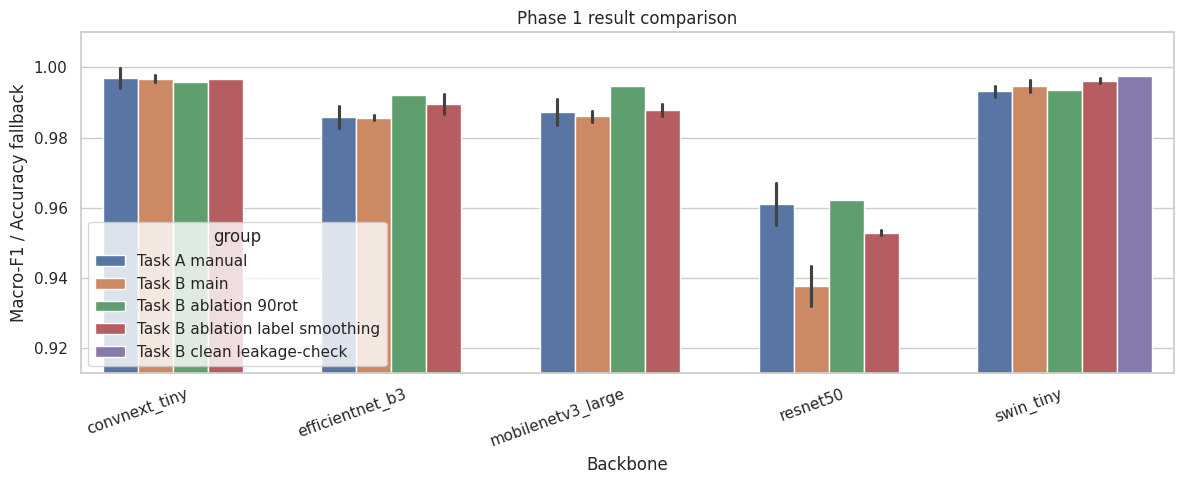

Saved: /home/sakana/Code/ManifoldsTeam/woodbench/reports/phase1_run_report/phase1_group_backbone_comparison.png


In [12]:
plot_df = raw_all.copy()
plot_df['score'] = plot_df['test_f1_macro'].fillna(plot_df['test_accuracy'])
plot_df = plot_df.dropna(subset=['score'])

if not plot_df.empty:
    plt.figure(figsize=(12, 5))
    sns.barplot(data=plot_df, x='backbone', y='score', hue='group', errorbar='sd')
    plt.ylabel('Macro-F1 / Accuracy fallback')
    plt.xlabel('Backbone')
    plt.ylim(max(0, plot_df['score'].min() - 0.02), min(1.01, plot_df['score'].max() + 0.02))
    plt.xticks(rotation=20, ha='right')
    plt.title('Phase 1 result comparison')
    plt.tight_layout()
    fig_path = REPORT_DIR / 'phase1_group_backbone_comparison.png'
    plt.savefig(fig_path, dpi=200)
    plt.show()
    print(f'Saved: {fig_path}')
else:
    print('No score available for plotting yet.')


In [13]:
task_b_main = raw_all[raw_all['group'].eq('Task B main')].copy()
rot = raw_all[raw_all['group'].eq('Task B ablation 90rot')].copy()

if not task_b_main.empty and not rot.empty:
    baseline = task_b_main.groupby('backbone')['test_f1_macro'].mean().rename('main_f1_mean')
    rot_score = rot.groupby('backbone')['test_f1_macro'].mean().rename('rot90_f1_mean')
    delta = pd.concat([baseline, rot_score], axis=1)
    delta['delta_rot90_minus_main'] = delta['rot90_f1_mean'] - delta['main_f1_mean']
    display(percent_table(delta.reset_index(), ['main_f1_mean', 'rot90_f1_mean', 'delta_rot90_minus_main']))
    delta.to_csv(REPORT_DIR / 'ablation_90rot_delta.csv')
else:
    print('Need both Task B main and 90rot rows to compute ablation delta.')


,backbone,main_f1_mean,rot90_f1_mean,delta_rot90_minus_main
0,convnext_tiny,99.68,99.59,-0.10
1,efficientnet_b3,98.56,99.23,0.66
2,mobilenetv3_large,98.61,99.46,0.85
3,resnet50,93.77,96.22,2.45
4,swin_tiny,99.46,99.35,-0.11


In [14]:
ls_df = raw_all[raw_all['group'].eq('Task B ablation label smoothing')].copy()
if not ls_df.empty:
    ls_pivot = ls_df.pivot_table(index='backbone', columns='label_smoothing', values='test_f1_macro', aggfunc='mean')
    display((ls_pivot * 100).round(2))
    ls_pivot.to_csv(REPORT_DIR / 'ablation_label_smoothing_pivot.csv')
else:
    print('No label smoothing rows found.')


label_smoothing,0.0,0.2
backbone,,
convnext_tiny,99.68,99.67
efficientnet_b3,98.76,99.15
mobilenetv3_large,98.68,98.92
resnet50,95.34,95.25
swin_tiny,99.57,99.68


In [15]:
clean_compare_metrics = [
    'best_epoch', 'best_val_acc', 'test_accuracy', 'test_f1_macro',
    'test_precision_macro', 'test_recall_macro'
]

swin_unclean = raw_all[
    raw_all['group'].eq('Task B ablation 90rot')
    & raw_all['backbone'].eq('swin_tiny')
    & raw_all['seed'].eq(42)
].copy()
swin_clean = raw_all[
    raw_all['group'].eq('Task B clean leakage-check')
    & raw_all['backbone'].eq('swin_tiny')
    & raw_all['seed'].eq(42)
].copy()

if swin_unclean.empty or swin_clean.empty:
    print('Missing Swin clean or unclean run for leakage comparison.')
else:
    compare_rows = []
    unclean_row = swin_unclean.iloc[0]
    clean_row = swin_clean.iloc[0]
    for label, row in [('unclean_90rot', unclean_row), ('clean_90rot', clean_row)]:
        item = {
            'data_version': label,
            'group': row.get('group'),
            'backbone': row.get('backbone'),
            'seed': row.get('seed'),
            'run_name': row.get('run_name'),
            'url': row.get('url'),
        }
        for metric in clean_compare_metrics:
            item[metric] = row.get(metric)
        compare_rows.append(item)

    delta = {'data_version': 'delta_clean_minus_unclean'}
    for metric in clean_compare_metrics:
        delta[metric] = clean_row.get(metric) - unclean_row.get(metric)
    compare_rows.append(delta)

    swin_clean_vs_unclean = pd.DataFrame(compare_rows)
    swin_clean_vs_unclean.to_csv(REPORT_DIR / 'swin_clean_vs_unclean_leakage_check.csv', index=False)

    display_cols = ['data_version', 'best_epoch', 'best_val_acc', 'test_accuracy', 'test_f1_macro', 'test_precision_macro', 'test_recall_macro', 'run_name', 'url']
    display_df = swin_clean_vs_unclean[display_cols].copy()
    percent_cols = ['best_val_acc', 'test_accuracy', 'test_f1_macro', 'test_precision_macro', 'test_recall_macro']
    for col in percent_cols:
        display_df[col] = (display_df[col] * 100).round(3)
    display(display_df)
    print(f"Saved: {REPORT_DIR / 'swin_clean_vs_unclean_leakage_check.csv'}")


,group,backbone,seed,state,test_accuracy,test_f1_macro,test_precision_macro,test_recall_macro,run_name,url
0,Task B ablation 90rot,swin_tiny,42,finished,99.35,99.35,99.41,99.33,swin_tiny_90rot_s42,https://wandb.ai/ny0g507h3p_/woodbench-taskB/r...
1,Task B clean leakage-check,swin_tiny,42,finished,99.76,99.76,99.73,99.80,swin_tiny_90rot_clean_s42,https://wandb.ai/ny0g507h3p_/woodbench-taskB/r...


## 6. Learning curves từ notebook output

Phần này trích learning curve trực tiếp từ output notebook vì không phải run nào cũng lưu W&B history đầy đủ.


In [16]:
# Learning curves are parsed from notebook outputs because not all runs store W&B history.
print(f"Notebook learning-curve rows: {len(notebook_learning_curves)}")
print(f"Saved: {REPORT_DIR / 'learning_curves_from_notebooks.csv'}")
print(f"Saved: {REPORT_DIR / 'best_epochs_from_learning_curves.csv'}")

if notebook_learning_curves.empty:
    print('No learning curves found in notebook outputs.')
else:
    curve_counts = (notebook_learning_curves
        .groupby(['group', 'backbone', 'seed', 'label_smoothing'], dropna=False)
        .agg(epochs=('epoch', 'nunique'), best_val_acc=('val_acc', 'max'))
        .reset_index()
        .sort_values(['group', 'backbone', 'seed', 'label_smoothing']))
    display(percent_table(curve_counts, ['best_val_acc']))

    task_b_main_curves = notebook_learning_curves[notebook_learning_curves['group'].eq('Task B main')].copy()
    if not task_b_main_curves.empty:
        plt.figure(figsize=(12, 5))
        sns.lineplot(
            data=task_b_main_curves,
            x='epoch', y='val_acc', hue='backbone', estimator='mean', errorbar='sd'
        )
        plt.title('Task B main learning curves from notebook logs')
        plt.ylabel('Validation accuracy')
        plt.xlabel('Epoch')
        plt.tight_layout()
        fig_path = REPORT_DIR / 'task_b_main_learning_curves_from_notebooks.png'
        plt.savefig(fig_path, dpi=200)
        plt.show()
        print(f'Saved: {fig_path}')

    swin_leak_curves = notebook_learning_curves[
        notebook_learning_curves['group'].isin(['Task B ablation 90rot', 'Task B clean leakage-check'])
        & notebook_learning_curves['backbone'].eq('swin_tiny')
        & notebook_learning_curves['seed'].eq(42)
    ].copy()
    if not swin_leak_curves.empty:
        plt.figure(figsize=(10, 5))
        sns.lineplot(data=swin_leak_curves, x='epoch', y='val_acc', hue='group', marker='o')
        plt.title('Swin-Tiny 90rot: clean vs unclean validation curve')
        plt.ylabel('Validation accuracy')
        plt.xlabel('Epoch')
        plt.tight_layout()
        fig_path = REPORT_DIR / 'swin_clean_vs_unclean_learning_curve.png'
        plt.savefig(fig_path, dpi=200)
        plt.show()
        print(f'Saved: {fig_path}')


history rows: 0


In [17]:
# W&B history plot is intentionally skipped here; notebook-output curves above are the canonical source for this report.
history_df = pd.DataFrame()


## 7. Checklist cuối cho báo cáo

Các dòng `False` là việc cần xử lý trước khi đưa bảng vào paper/report.


In [18]:
checks = []
expected_counts = manifest.groupby('group').size().to_dict()
actual_counts = raw_all.groupby('group').size().to_dict()
for group, expected in expected_counts.items():
    actual = actual_counts.get(group, 0)
    checks.append({'check': f'{group}: expected rows present', 'ok': actual == expected, 'detail': f'{actual}/{expected}'})

for group in ['Task B main', 'Task B ablation 90rot', 'Task B ablation label smoothing', 'Task B clean leakage-check']:
    subset = raw_all[raw_all['group'].eq(group)]
    if not subset.empty:
        checks.append({'check': f'{group}: W&B runs not missing', 'ok': not subset['state'].eq('missing').any(), 'detail': subset['state'].value_counts().to_dict()})

checks.append({'check': 'Task A manual metrics parsed', 'ok': task_a_missing.empty, 'detail': f'{len(task_a_missing)} rows need review'})
checks.append({'check': 'Required metrics found or reported', 'ok': True, 'detail': f'{len(missing_metrics)} missing metric cells listed in missing_metrics.csv'})
checks.append({'check': 'WoodID plan exists', 'ok': PLAN_PATH.exists(), 'detail': str(PLAN_PATH.relative_to(ROOT))})
checks.append({'check': 'Report cache saved', 'ok': (REPORT_DIR / 'phase1_all_runs_raw.csv').exists(), 'detail': str(REPORT_DIR.relative_to(ROOT))})

checklist = pd.DataFrame(checks)
checklist.to_csv(REPORT_DIR / 'phase1_report_checklist.csv', index=False)
checklist


,check,ok,detail
0,Task A manual: expected rows present,True,15/15
1,Task B ablation 90rot: expected rows present,True,5/5
2,Task B ablation label smoothing: expected rows...,True,10/10
3,Task B clean leakage-check: expected rows present,True,1/1
4,Task B main: expected rows present,True,15/15
5,Task B main: W&B runs not missing,True,{'finished': 15}
6,Task B ablation 90rot: W&B runs not missing,True,{'finished': 5}
7,Task B ablation label smoothing: W&B runs not ...,True,{'finished': 10}
8,Task B clean leakage-check: W&B runs not missing,True,{'finished': 1}
9,Task A manual metrics parsed,True,0 rows need review
